In [19]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)

tf.keras.utils.set_random_seed(42)

data = np.load("../data/sign_mnist_prepared.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

with open("../data/idx_to_letter.json") as f:
    idx_to_letter = {int(k): v for k, v in json.load(f).items()}
letters = [idx_to_letter[i] for i in range(24)]

In [20]:
def build_cnn():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(24, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model = build_cnn()

In [21]:
augment_strong = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(height_factor=(-0.3, 0.3), width_factor=(-0.3, 0.3)),
    layers.RandomTranslation(0.15, 0.15),
    layers.RandomBrightness(0.3, value_range=(0, 1)),
    layers.RandomContrast(0.4),
    layers.GaussianNoise(0.05),
], name="augmentation_forte")

def apply_aug(x, y):
    x = augment_strong(x, training=True)
    return tf.clip_by_value(x, 0.0, 1.0), y

In [22]:
n_val = int(0.15 * len(X_train))
perm = np.random.default_rng(42).permutation(len(X_train))
val_idx, tr_idx = perm[:n_val], perm[n_val:]

X_val, y_val = X_train[val_idx], y_train[val_idx]
X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]

train_ds = (tf.data.Dataset.from_tensor_slices((X_tr, y_tr))
            .shuffle(10000, seed=42)
            .batch(64)
            .map(apply_aug, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(64)

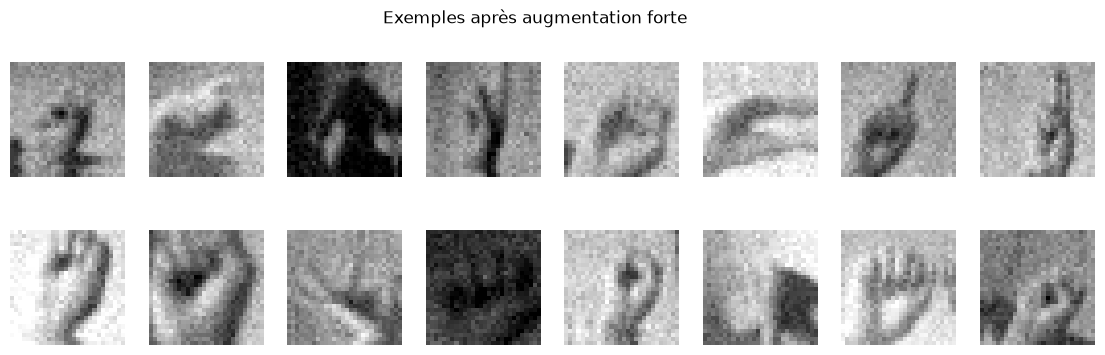

In [23]:
x_batch, _ = next(iter(train_ds))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img in zip(axes.ravel(), x_batch[:16]):
    ax.imshow(img.numpy().squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Exemples après augmentation forte")
plt.show()

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=3, min_lr=1e-5),
]

start = time.time()
history = model.fit(train_ds, validation_data=val_ds,
                    epochs=50, callbacks=callbacks, verbose=1)
print(f"Temps d'entraînement : {time.time() - start:.0f} s")

Epoch 1/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 49s 117ms/step - accuracy: 0.2256 - loss: 2.7430 - val_accuracy: 0.2171 - val_loss: 2.7706 - learning_rate: 0.0010
Epoch 2/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 47s 128ms/step - accuracy: 0.5158 - loss: 1.4960 - val_accuracy: 0.7368 - val_loss: 0.7957 - learning_rate: 0.0010
Epoch 3/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 42s 113ms/step - accuracy: 0.6614 - loss: 1.0257 - val_accuracy: 0.9390 - val_loss: 0.2436 - learning_rate: 0.0010
Epoch 4/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 46s 125ms/step - accuracy: 0.7365 - loss: 0.7775 - val_accuracy: 0.9349 - val_loss: 0.2277 - learning_rate: 0.0010
Epoch 5/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 50s 137ms/step - accuracy: 0.7851 - loss: 0.6303 - val_accuracy: 0.9767 - val_loss: 0.0987 - learning_rate: 0.0010
Epoch 6/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 46s 126ms/step - accuracy: 0.8237 - loss: 0.5164 - val_accuracy: 0.9786 - val_loss: 0.0820 - learning_rate: 0.0010
Epoch 7/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 51s 140ms/step - accuracy: 0.8

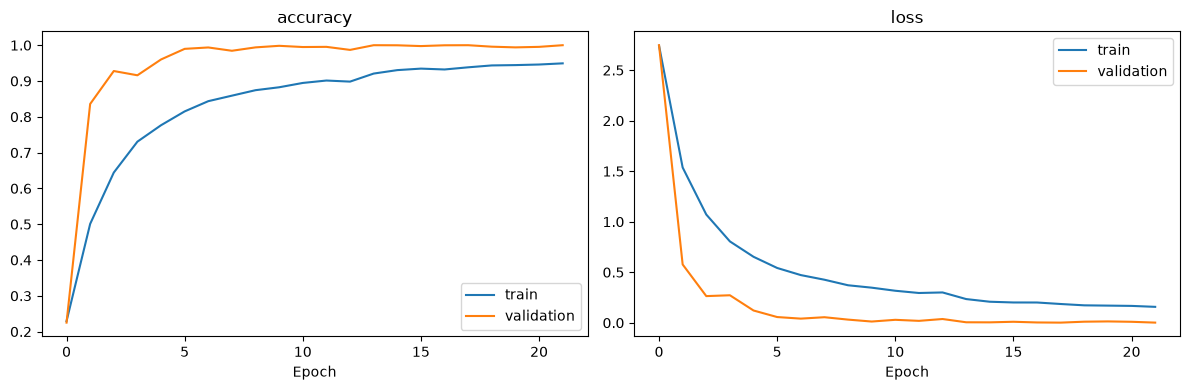

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ["accuracy", "loss"]):
    ax.plot(history.history[m], label="train")
    ax.plot(history.history[f"val_{m}"], label="validation")
    ax.set_title(m); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()

In [8]:
proba = model.predict(X_test, verbose=0)
y_pred = proba.argmax(axis=1)

res_robust = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision_macro": float(precision_score(y_test, y_pred, average="macro", zero_division=0)),
    "recall_macro": float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
    "f1_macro": float(f1_score(y_test, y_pred, average="macro")),
}
print({k: round(v, 4) for k, v in res_robust.items()})
print("Accuracy >= 90 % :", "OK" if res_robust["accuracy"] >= 0.90 else "NON ATTEINT")
print("F1 macro >= 90 % :", "OK" if res_robust["f1_macro"] >= 0.90 else "NON ATTEINT")

{'accuracy': 0.9999, 'precision_macro': 0.9997, 'recall_macro': 0.9999, 'f1_macro': 0.9998}
Accuracy >= 90 % : OK
F1 macro >= 90 % : OK


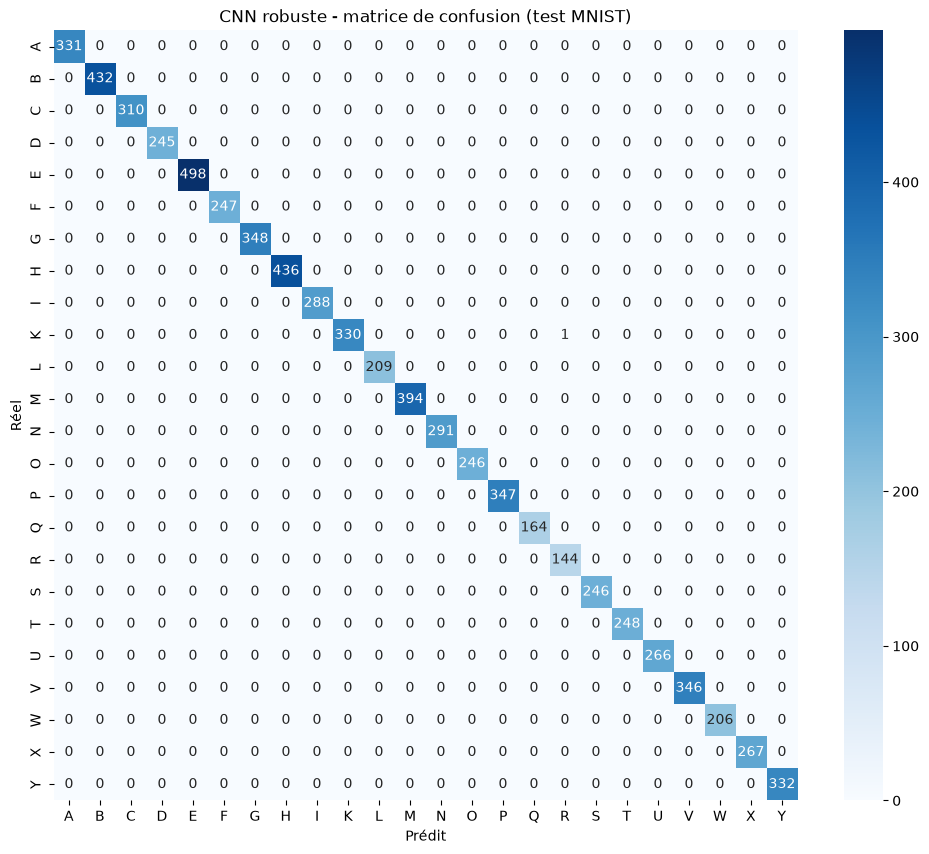

              precision    recall  f1-score   support

           A      1.000     1.000     1.000       331
           B      1.000     1.000     1.000       432
           C      1.000     1.000     1.000       310
           D      1.000     1.000     1.000       245
           E      1.000     1.000     1.000       498
           F      1.000     1.000     1.000       247
           G      1.000     1.000     1.000       348
           H      1.000     1.000     1.000       436
           I      1.000     1.000     1.000       288
           K      1.000     0.997     0.998       331
           L      1.000     1.000     1.000       209
           M      1.000     1.000     1.000       394
           N      1.000     1.000     1.000       291
           O      1.000     1.000     1.000       246
           P      1.000     1.000     1.000       347
           Q      1.000     1.000     1.000       164
           R      0.993     1.000     0.997       144
           S      1.000    

In [9]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=letters, yticklabels=letters)
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title("CNN robuste - matrice de confusion (test MNIST)")
plt.show()

print(classification_report(y_test, y_pred, target_names=letters, digits=3))

In [10]:
model.save("../data/cnn_robuste.keras")

with open("../docs/results.json") as f:
    results = json.load(f)
results["cnn_robuste"] = res_robust
with open("../docs/results.json", "w") as f:
    json.dump(results, f, indent=2)

In [11]:
models = {
    "CNN amélioré": keras.models.load_model("../data/cnn_final.keras"),
    "CNN robuste": keras.models.load_model("../data/cnn_robuste.keras"),
}

rows = []
for name, m in models.items():
    p = m.predict(X, verbose=0)
    pred = p.argmax(1)
    rows.append({
        "Modèle": name,
        "Accuracy photos": round(float((pred == df["y"].values).mean()), 3),
        "F1 macro photos": round(float(f1_score(df["y"], pred, average="macro")), 3),
        "Confiance moyenne": round(float(p.max(1).mean()), 3),
    })

comparison = pd.DataFrame(rows)
print(f"{len(df)} photos")
print(comparison.to_string(index=False))

NameError: name 'X' is not defined

In [ ]:
print(df.groupby("letter").size())